In [4]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np    

from src.data import load_adult

pd.set_option("display.max_columns", None)

train = load_adult("train")

print(train.shape)

(32561, 15)


## 1. 첫인상: 데이터는 어떻게 생겼나?
- 앞 몇 줄 확인
- 각 항목의 자료형(숫자 / 글자)
- 항목별 서로 다른 값의 개수

In [7]:
# 위에서부터 5줄을 보여준다. 괄호 안에 숫자를 넣으면 그만큼 보여준다. 예: train.head(10)
train.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [8]:
# info()는 각 열의
#   - Non-Null Count: 빈 칸(NaN)이 아닌 값의 개수
#   - Dtype: 자료형 (int64 = 정수, str = 글자)
# 와 메모리 사용량을 한 번에 보여준다.
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [9]:
TARGET = "income"

numeric_cols = train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in train.select_dtypes(include="str").columns if c != TARGET]

print("Numeric Features: ", numeric_cols)
print("Categorical Features: ", categorical_cols)

Numeric Features:  ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical Features:  ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [10]:
# nunique(): 각 열에 서로 다른 값이 몇 종류 있는지 센다 (빈 칸은 세지 않음).
# sort_values(): 개수 기준으로 정렬한다.
train.nunique().sort_values()

sex                   2
income                2
race                  5
relationship          6
marital-status        7
workclass             8
occupation           14
education            16
education-num        16
native-country       41
age                  73
capital-loss         92
hours-per-week       94
capital-gain        119
fnlwgt            21648
dtype: int64

In [11]:
# crosstab(교차표): 두 열의 값 조합이 각각 몇 번 나오는지 센 표.
# 만약 한 education 값이 항상 하나의 education-num 값과만 짝지어진다면
# 두 열은 같은 정보이므로, 모델에는 하나만 넣으면 된다.
pd.crosstab(train["education"], train["education-num"])

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,933,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1175,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,433,0,0,0,0,0,0,0,0
1st-4th,0,168,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,333,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,646,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,514,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1067,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,1382,0,0,0,0,0


In [12]:
# 정답 열에 어떤 값이 있는지 확인한다.
# '<=50K', '>50K' 두 종류만 나와야 한다.
print("학습 데이터 정답 값:", train[TARGET].unique())

# 테스트 데이터는 분석에 쓰지 않고, "형식이 학습 데이터와 같은지"만 확인한다.
# (data.py에서 마침표를 제거했으므로 '<=50K.' 같은 값이 없어야 한다)
test = load_adult("test")
print("테스트 데이터 크기:", test.shape)             # (16281, 15)가 나와야 한다
print("테스트 데이터 정답 값:", test[TARGET].unique())

학습 데이터 정답 값: <StringArray>
['<=50K', '>50K']
Length: 2, dtype: str
테스트 데이터 크기: (16281, 15)
테스트 데이터 정답 값: <StringArray>
['<=50K', '>50K']
Length: 2, dtype: str


### 첫인상 정리
- 학습 데이터 32,561행, 테스트 데이터 16,281행. 항목 14개 + 정답(income) 1개
- 숫자 항목 6개: age, fnlwgt, education-num, capital-gain, capital-loss, hours-per-week
- 글자 항목 8개: workclass, education, marital-status, occupation, relationship, race, sex, native-country
- 정답 값은 학습/테스트 모두 `<=50K`, `>50K` 두 종류 → 테스트 파일의 마침표 문제는 해결됨
- 빈 칸: workclass 1,836개, occupation 1,843개, native-country 583개 → 다음 단계에서 분석
- education과 education-num은 1대1 대응(교차표에서 행마다 값이 한 칸에만 있음) → 같은 정보이므로 모델에는 순서 정보가 있는 education-num만 사용 예정
- fnlwgt는 서로 다른 값이 21,648개 → 개인 특성이 아닌 인구 조사 표본 가중치이므로 사용 여부 검토 필요
- native-country는 41종류로 많음 → one-hot encoding 시 열이 크게 늘어남
- sex는 2종류(이진 값), race 5종류, relationship 6종류, marital-status 7종류

## 2. 빈 칸 (Missing Values)
- 어떤 항목에 빈 칸이 몇 개, 몇 % 있는가?
- 빈 칸들이 같은 행에 함께 나타나는가?
- 빈 칸인 사람은 고소득자 비율이 다른가? → 전처리 방법 결정에 사용

In [13]:
# isna(): 각 칸이 빈 칸(NaN)이면 True, 아니면 False인 표를 만든다.
# sum(): True는 1, False는 0으로 계산되므로, 열마다 더하면 빈 칸 개수가 된다.
missing = train.isna().sum()

# 전체 행 개수로 나누고 100을 곱해 퍼센트로 바꾼다.
missing_pct = missing / len(train) * 100

# 두 결과를 하나의 표로 묶는다. round(2): 소수점 둘째 자리까지 반올림
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct.round(2),
})

# 빈 칸이 하나라도 있는 항목만 골라서 보여준다.
missing_table[missing_table["missing_count"] > 0]

,missing_count,missing_pct
workclass,1836,5.64
occupation,1843,5.66
native-country,583,1.79


In [14]:
# any(axis=1): 한 행(가로 방향)에서 True가 하나라도 있으면 True
#   axis=0 → 열 방향(세로)으로 계산, axis=1 → 행 방향(가로)으로 계산
rows_with_na = train.isna().any(axis=1)

print("빈 칸이 있는 행 개수:", rows_with_na.sum())
# True/False의 평균 = True의 비율
print(f"전체 대비 비율: {rows_with_na.mean() * 100:.2f}%")

빈 칸이 있는 행 개수: 2399
전체 대비 비율: 7.37%


In [15]:
# 두 열의 "빈 칸 여부(True/False)"로 교차표를 만든다.
# rownames, colnames: 표의 행/열 이름
# margins=True: 맨 아래와 맨 오른쪽에 합계(All)를 추가
pd.crosstab(
    train["workclass"].isna(),
    train["occupation"].isna(),
    rownames=["workclass is NaN"],
    colnames=["occupation is NaN"],
    margins=True,
)

occupation is NaN,False,True,All
workclass is NaN,,,
False,30718,7,30725
True,0,1836,1836
All,30718,1843,32561


In [16]:
# 조건 두 개를 & (그리고)로 묶는다. 각 조건은 반드시 괄호로 감싸야 한다.
#   occupation은 빈 칸  AND  workclass는 값이 있음 (notna = isna의 반대)
only_occ_na = train["occupation"].isna() & train["workclass"].notna()

# loc[행 조건, 열 이름]: 조건에 맞는 행에서 원하는 열만 꺼낸다.
# value_counts(): 값별 개수를 센다.
train.loc[only_occ_na, "workclass"].value_counts()

workclass
Never-worked    7
Name: count, dtype: int64

In [17]:
# 정답을 True/False로 바꾼다: 고소득자(>50K)면 True
is_high = train[TARGET] == ">50K"
print(f"전체 고소득자 비율: {is_high.mean() * 100:.1f}%\n")

# 빈 칸이 있는 항목 목록 (셀 2의 결과 재사용)
na_cols = missing[missing > 0].index.tolist()

rows = []
for col in na_cols:
    is_na = train[col].isna()
    rows.append({
        "feature": col,
        # is_high[is_na]: 빈 칸인 사람들만 골라서 고소득자 비율 계산
        "high_income_pct_if_NaN": is_high[is_na].mean() * 100,
        # ~ 는 True/False를 뒤집는다 → 값이 있는 사람들
        "high_income_pct_if_present": is_high[~is_na].mean() * 100,
    })

na_vs_income = pd.DataFrame(rows).round(1)
na_vs_income

전체 고소득자 비율: 24.1%



,feature,high_income_pct_if_NaN,high_income_pct_if_present
0,workclass,10.4,24.9
1,occupation,10.4,24.9
2,native-country,25.0,24.1


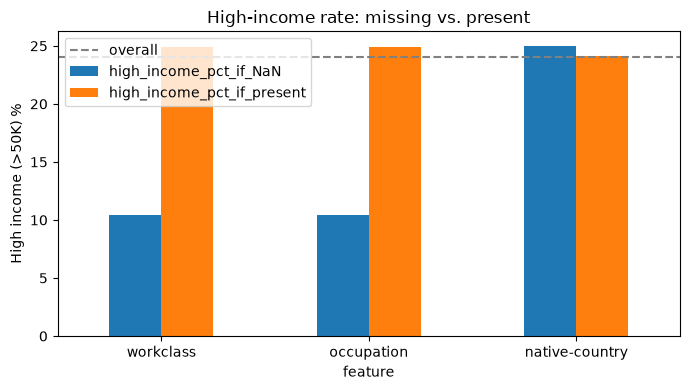

In [18]:
# 표 형태를 그래프 그리기 좋게 바꾼다.
# set_index("feature"): feature 열을 행 이름으로 사용 → 그래프의 x축이 된다.
ax = na_vs_income.set_index("feature").plot(
    kind="bar",            # 막대그래프
    figsize=(7, 4),        # 그림 크기 (가로, 세로) 인치 단위
    rot=0,                 # x축 글자를 회전하지 않음
)

# 전체 고소득자 비율을 점선으로 표시해서 비교 기준으로 삼는다.
ax.axhline(is_high.mean() * 100, color="gray", linestyle="--", label="overall")

ax.set_ylabel("High income (>50K) %")
ax.set_title("High-income rate: missing vs. present")
ax.legend()
plt.tight_layout()         # 글자가 잘리지 않게 여백 자동 조정
plt.show()

### 빈 칸 정리
- 빈 칸 비율: workclass 5.64%, occupation 5.66%, native-country 1.79%
- 빈 칸이 하나라도 있는 행: 2,399개 (7.37%) → 세 항목의 빈 칸이 같은 행에 겹쳐 있음
- workclass가 빈 칸이면 occupation도 항상 빈 칸 (1,836명)
- occupation만 빈 칸인 7명은 모두 workclass가 Never-worked → 응답 거부가 아니라 적을 직업이 없었던 것
- 빈 칸일 때 고소득자 비율: workclass/occupation 10.4% (값이 있으면 24.9%), native-country 25.0% (값이 있으면 24.1%)
- 해석: workclass/occupation의 빈 칸은 무작위가 아니라 소득이 낮은 사람에게 몰려 있음 → 빈 칸 자체가 정보
- 결론: 행을 지우지 않고, 세 항목 모두 "Missing"이라는 별도 값으로 처리 (전처리 Pipeline에서 SimpleImputer 사용)

## 3. 정답 비율 (Class Balance)
- 50K 이하 / 50K 초과가 각각 몇 명, 몇 %인가?
- 불균형이 평가 지표와 모델 학습에 주는 영향

In [19]:
# value_counts(): 값별 개수를 센다 (많은 순으로 정렬됨)
label_counts = train[TARGET].value_counts()

# normalize=True: 개수 대신 비율(0~1)로 계산한다. 100을 곱해 퍼센트로 바꾼다.
label_pct = train[TARGET].value_counts(normalize=True) * 100

label_table = pd.DataFrame({
    "count": label_counts,
    "pct": label_pct.round(2),
})
label_table

,count,pct
income,,
<=50K,24720,75.92
>50K,7841,24.08


In [20]:
# 불균형 비율: 많은 쪽 개수 ÷ 적은 쪽 개수
# "다수 클래스가 소수 클래스보다 몇 배 많은가"를 뜻한다.
imbalance_ratio = label_counts.max() / label_counts.min()
print(f"불균형 비율 (다수 : 소수) = {imbalance_ratio:.2f} : 1")

# 항상 다수 클래스(<=50K)만 답하는 모델의 정확도 = 다수 클래스의 비율
# 앞으로 만들 모든 모델은 최소한 이 숫자보다는 높아야 의미가 있다.
print(f"Dummy 모델(항상 '<=50K'만 예측)의 정확도: {label_pct.max():.2f}%")

불균형 비율 (다수 : 소수) = 3.15 : 1
Dummy 모델(항상 '<=50K'만 예측)의 정확도: 75.92%


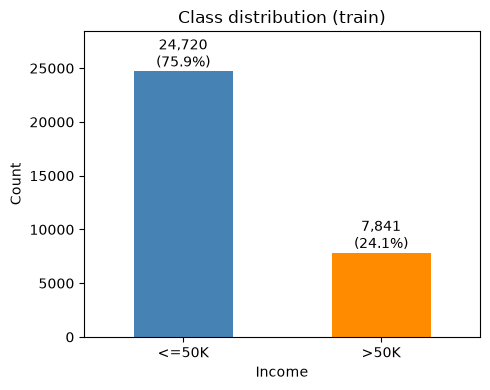

In [21]:
ax = label_counts.plot(
    kind="bar",
    figsize=(5, 4),
    rot=0,
    color=["steelblue", "darkorange"],   # 막대마다 색을 다르게
)

# 막대 위에 "개수 (비율)"을 글자로 표시한다.
#   zip(a, b): 두 목록에서 같은 위치의 값을 하나씩 짝지어 꺼낸다.
#   {c:,}: 천 단위마다 쉼표를 넣는다 (예: 24720 → 24,720)
labels = [f"{c:,}\n({p:.1f}%)" for c, p in zip(label_counts, label_pct)]

# ax.containers[0]: 그래프에 그려진 막대들의 묶음
# bar_label(): 각 막대 위에 글자를 붙인다.
ax.bar_label(ax.containers[0], labels=labels)

# 막대 위 글자가 그래프 밖으로 잘리지 않게 y축 위쪽에 15% 여유를 둔다.
ax.set_ylim(0, label_counts.max() * 1.15)

ax.set_xlabel("Income")
ax.set_ylabel("Count")
ax.set_title("Class distribution (train)")
plt.tight_layout()
plt.show()

In [22]:
# 정답 비율만 확인하는 것은 모델링 결정에 영향을 주지 않으므로 괜찮다.
# 목적: 학습과 테스트의 정답 비율이 비슷해야 "학습 때의 성능이 테스트에서도 비슷하게 나온다"고 기대할 수 있다.
comparison = pd.DataFrame({
    "train_pct": train[TARGET].value_counts(normalize=True) * 100,
    "test_pct": test[TARGET].value_counts(normalize=True) * 100,
}).round(2)
comparison

,train_pct,test_pct
income,,
<=50K,75.92,76.38
>50K,24.08,23.62


### 정답 비율 정리
- <=50K: 24,720명 (75.92%), >50K: 7,841명 (24.08%)
- 불균형 비율 3.15 : 1 → 중간 정도의 불균형 (SMOTE 같은 데이터 증강까지는 필요 없는 수준)
- 항상 '<=50K'만 예측하는 Dummy 모델의 정확도가 75.92% → 50K 초과를 한 명도 못 찾는데도 정확도는 높음 → 정확도만으로는 모델을 평가할 수 없음
- 테스트 데이터의 정답 비율: 76.38% / 23.62% → 학습 데이터와 비슷함 (차이 0.5%p 이내)
- 대응: ROC-AUC, PR-AUC, F1, balanced accuracy, confusion matrix 사용 / Dummy 기준선 포함 / StratifiedKFold 사용 / class_weight="balanced" 실험

## 4. 숫자 항목 통계와 분포
- 평균, 분산, 범위, 치우침(skewness)
- 이상해 보이는 값 확인
- 50K 초과 / 이하 그룹 간 분포 비교
- 전처리에 주는 의미 (scaling, 로그 변환)

In [23]:
# describe(): 숫자 열마다 개수, 평균, 표준편차, 최솟값, 사분위수, 최댓값을 계산한다.
# .T: 표를 뒤집는다(transpose). 항목이 행으로 오게 해서 읽기 쉽게 만든다.
stats = train[numeric_cols].describe().T

# 과제 요구사항인 "분산"을 추가한다. (분산 = 표준편차의 제곱)
stats["var"] = train[numeric_cols].var()

# skew(): 치우침 정도(왜도, skewness)
#   0 근처 → 좌우 대칭
#   양수   → 오른쪽으로 꼬리가 긴 분포 (대부분 작은 값이고, 큰 값이 드물게 있음)
#   절댓값이 1보다 크면 많이 치우친 것으로 본다.
stats["skew"] = train[numeric_cols].skew()

# 값이 0인 비율(%). 0이 대부분인 항목을 찾기 위해서다.
stats["zero_pct"] = (train[numeric_cols] == 0).mean() * 100

stats.round(2)

,count,mean,std,min,25%,50%,75%,max,var,skew,zero_pct
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0,1.860600e+02,0.56,0.00
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0,1.114080e+10,1.45,0.00
education-num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,6.620000e+00,-0.31,0.00
capital-gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0,5.454254e+07,11.95,91.67
capital-loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0,1.623769e+05,4.59,95.33
hours-per-week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,1.524600e+02,0.23,0.00


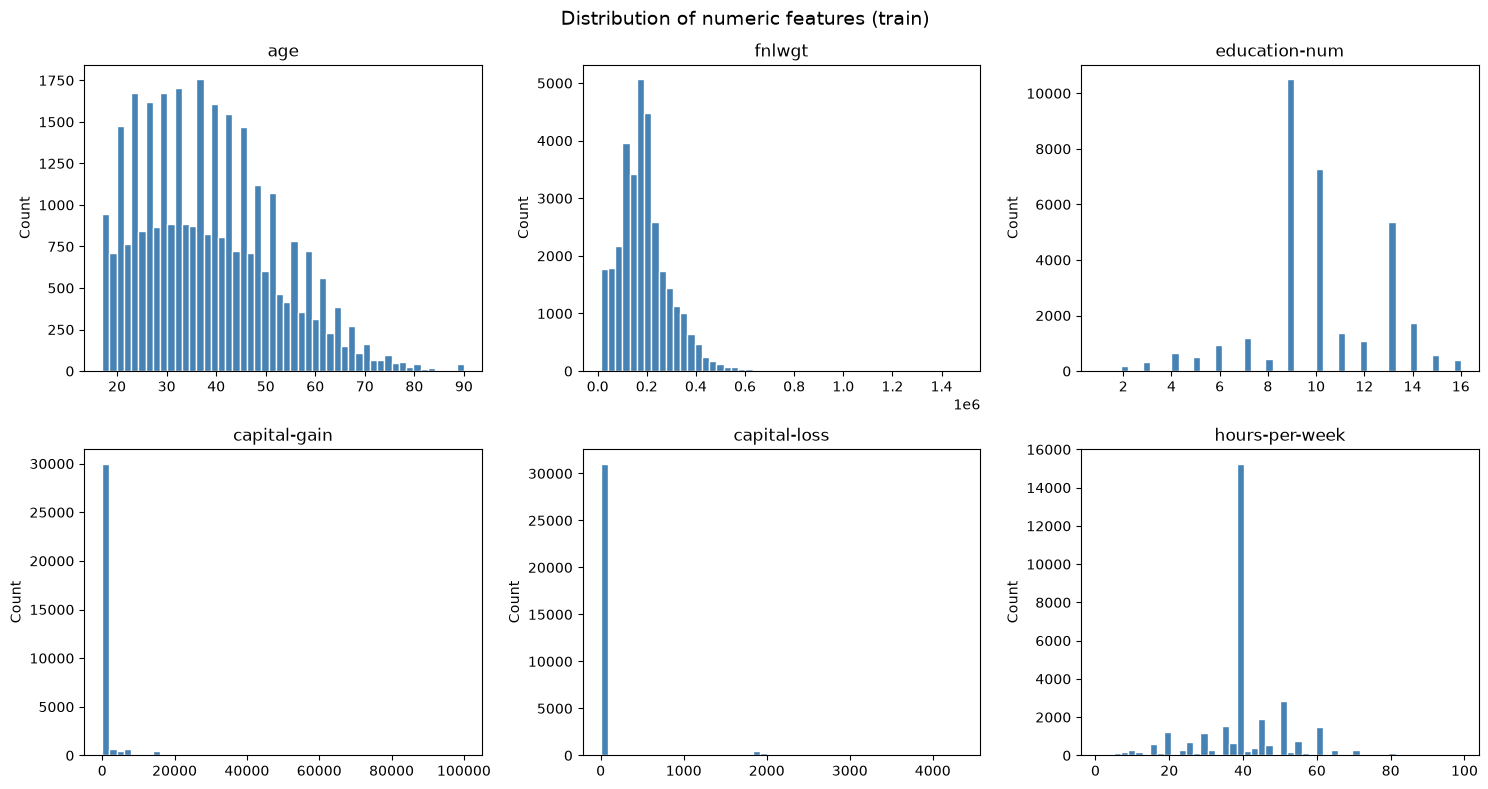

In [24]:
# plt.subplots(행, 열): 그래프 여러 개를 격자 모양으로 한 번에 만든다.
# fig = 전체 그림, axes = 각 칸의 그래프들 (2x3 배열)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# axes.flatten(): 2x3 배열을 6개짜리 1줄로 펼친다 → 항목 6개와 짝짓기 쉬워진다.
for ax, col in zip(axes.flatten(), numeric_cols):
    # hist(): 히스토그램. 값의 범위를 bins개 구간으로 나누고, 구간마다 몇 명인지 막대로 그린다.
    ax.hist(train[col], bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Count")

fig.suptitle("Distribution of numeric features (train)", fontsize=14)   # 전체 제목
plt.tight_layout()
plt.show()

In [25]:
# is_high는 2단계에서 만든 변수 (고소득자면 True)

for col in ["capital-gain", "capital-loss"]:
    nonzero = train[col] > 0          # 0이 아닌 사람 = 실제로 자본 이득/손실이 있었던 사람

    print(f"[{col}]")
    print(f"  0인 비율:                   {(~nonzero).mean() * 100:.1f}%")
    print(f"  0일 때 고소득자 비율:       {is_high[~nonzero].mean() * 100:.1f}%")
    print(f"  0이 아닐 때 고소득자 비율:  {is_high[nonzero].mean() * 100:.1f}%")
    print()

[capital-gain]
  0인 비율:                   91.7%
  0일 때 고소득자 비율:       20.7%
  0이 아닐 때 고소득자 비율:  61.8%

[capital-loss]
  0인 비율:                   95.3%
  0일 때 고소득자 비율:       22.8%
  0이 아닐 때 고소득자 비율:  50.9%



In [26]:
# 셀 2에서 최댓값이 유난히 "딱 떨어지는" 값이 있었다. 몇 명이고, 어떤 사람들인지 확인한다.
# 딕셔너리 {이름: 조건}: 확인할 조건들을 이름과 함께 묶어둔다.
checks = {
    "capital-gain == 99999": train["capital-gain"] == 99999,
    "hours-per-week == 99":  train["hours-per-week"] == 99,
    "age == 90":             train["age"] == 90,
}

# items(): 딕셔너리에서 (이름, 조건)을 한 쌍씩 꺼낸다.
for name, mask in checks.items():
    print(f"{name:25s} {mask.sum():4d}명 | 고소득자 비율 {is_high[mask].mean() * 100:5.1f}%")

capital-gain == 99999      159명 | 고소득자 비율 100.0%
hours-per-week == 99        85명 | 고소득자 비율  29.4%
age == 90                   43명 | 고소득자 비율  18.6%


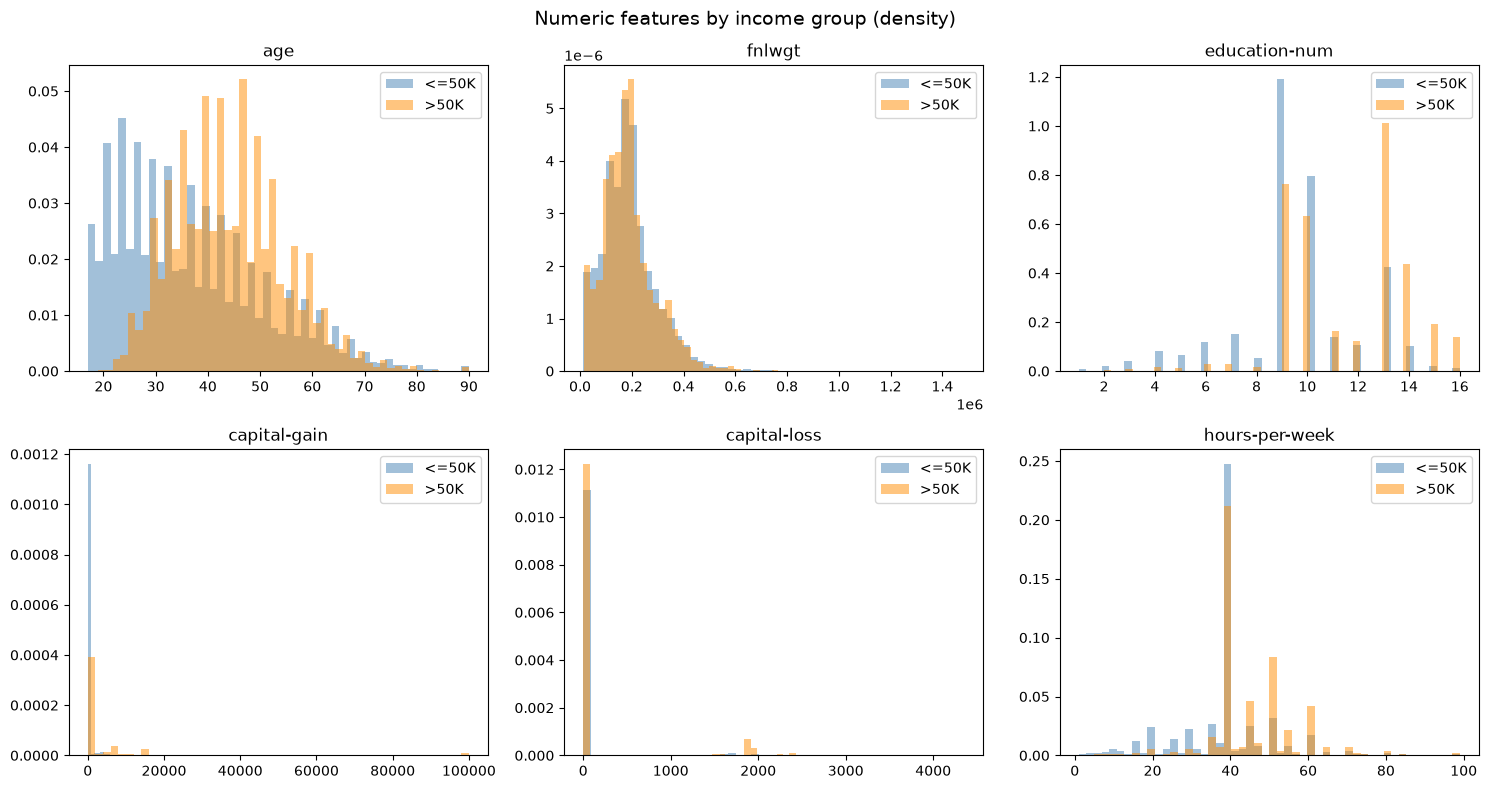

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    # 두 그룹을 같은 그래프에 반투명하게 겹쳐 그린다.
    for label, color in [("<=50K", "steelblue"), (">50K", "darkorange")]:
        group = train.loc[train[TARGET] == label, col]
        ax.hist(
            group,
            bins=50,
            density=True,   # 개수 대신 "비율"로 그린다 (아래 설명 참고)
            alpha=0.5,      # 투명도 (0=투명, 1=불투명) → 겹친 부분도 보이게
            color=color,
            label=label,
        )
    ax.set_title(col)
    ax.legend()

fig.suptitle("Numeric features by income group (density)", fontsize=14)
plt.tight_layout()
plt.show()

In [28]:
# 그래프로 본 차이를 숫자로 확인한다.
# groupby(TARGET): 정답(<=50K / >50K)별로 묶는다.
# agg(["mean", "median"]): 그룹마다 평균과 중앙값을 계산한다.
# .T: 항목이 행으로 오게 뒤집는다.
train.groupby(TARGET)[numeric_cols].agg(["mean", "median"]).T.round(1)

income                    <=50K      >50K
age            mean        36.8      44.2
               median      34.0      44.0
fnlwgt         mean    190340.9  188005.0
               median  179465.0  176101.0
education-num  mean         9.6      11.6
               median       9.0      12.0
capital-gain   mean       148.8    4006.1
               median       0.0       0.0
capital-loss   mean        53.1     195.0
               median       0.0       0.0
hours-per-week mean        38.8      45.5
               median      40.0      40.0

In [29]:
# np.log1p(x) = log(1 + x)
#   그냥 log(x)를 쓰면 x=0일 때 계산이 안 되므로(-무한대), 1을 더한 뒤 로그를 취한다.
#   큰 값은 많이 줄이고 작은 값은 조금만 줄여서, 오른쪽으로 긴 꼬리를 짧게 만든다.
for col in ["capital-gain", "capital-loss", "fnlwgt"]:
    before = train[col].skew()
    after = np.log1p(train[col]).skew()
    print(f"{col:15s} skew: {before:6.2f}  →  log1p 후: {after:6.2f}")

capital-gain    skew:  11.95  →  log1p 후:   3.10
capital-loss    skew:   4.59  →  log1p 후:   4.31
fnlwgt          skew:   1.45  →  log1p 후:  -0.84


In [30]:
# workclass가 빈 칸인 사람은 왜 고소득자 비율이 낮을까?
# 가설: 은퇴자, 학생 등 "현재 일하지 않는 사람"이라서 → 나이가 많거나 적고, 근무 시간이 짧을 것
train.groupby(train["workclass"].isna())[["age", "hours-per-week"]].agg(["mean", "median"]).round(1)

age        hours-per-week       
           mean median           mean median
workclass                                   
False      38.4   37.0           40.9   40.0
True       41.0   35.0           31.9   36.0

### 숫자 항목 정리
- 범위 차이: fnlwgt는 12,285~1,484,705, education-num은 1~16 → 항목마다 크기 단위가 크게 다름 → scaling 필요 (k-NN, SVM, Perceptron, 선형 모델)
- 치우침: capital-gain skew 11.95, capital-loss skew 4.59 (값의 91.67%, 95.33%가 0). fnlwgt skew 1.45. age(0.56), education-num(-0.31), hours-per-week(0.23)은 비교적 대칭
- hours-per-week는 46.7%가 정확히 40시간 → 주 40시간 근무에 크게 몰려 있음
- capital-gain이 0이 아닐 때 고소득자 비율 61.8% (0일 때 20.7%), capital-loss는 50.9% (0일 때 22.8%) → "0인가 아닌가" 자체가 강한 정보
- 상한값: capital-gain 99999 159명 (고소득자 비율 100%), hours-per-week 99 85명 (29.4%), age 90 43명 (18.6%) → 상한값 처리(top-coding)로 보고 그대로 둠
- 50K 초과 그룹이 이하 그룹보다: 나이 많음 (평균 44.2세 vs 36.8세), 교육 수준 높음 (education-num 11.6 vs 9.6), 근무 시간 김 (45.5시간 vs 38.8시간)
- capital-gain은 두 그룹 모두 중앙값 0이지만 평균은 4,006 vs 149 → 소수의 큰 값이 평균을 끌어올림
- fnlwgt는 두 그룹 분포가 거의 같음 (평균 188,005 vs 190,341) → 정답과 관계가 약함 → 제외 검토
- 로그 변환(log1p) 후 skew: capital-gain 11.95 → 3.10, capital-loss 4.59 → 4.31, fnlwgt 1.45 → -0.84 → capital-loss는 0이 95%라 로그 변환 효과가 거의 없음 → "0인가 아닌가" 열 추가도 고려
- workclass가 빈 칸인 사람: 평균 근무 시간 31.9시간 (값이 있으면 40.9시간). 25세 미만 34.4%, 60세 이상 28.5% (값이 있으면 16.1%, 6.9%) → 가설(학생, 은퇴자 등 현재 일하지 않는 사람) 맞음

## 5. 글자 항목별 고소득자 비율
- 항목의 값마다 고소득자 비율 비교
- 드문 값(rare category) 확인
- 서로 겹치는 정보를 가진 항목 확인
- 전처리에 주는 의미 (one-hot encoding, 드문 값 묶기)

In [31]:
def category_summary(col):
    """글자 항목 하나에 대해, 값마다 인원수, 비율, 고소득자 비율을 계산한 표를 돌려준다."""
    # 2단계에서 빈 칸을 "Missing"이라는 값으로 처리하기로 했으므로, 여기서도 똑같이 보여준다.
    # fillna(값): 빈 칸(NaN)을 지정한 값으로 채운다. (원본 train은 바뀌지 않음)
    values = train[col].fillna("Missing")

    summary = pd.DataFrame({
        "count": values.value_counts(),
        "pct": (values.value_counts(normalize=True) * 100).round(2),
        # is_high를 값별로 묶어서 평균 → 값마다 고소득자 비율
        "high_income_pct": (is_high.groupby(values).mean() * 100).round(1),
    })

    # 고소득자 비율이 높은 순으로 정렬
    return summary.sort_values("high_income_pct", ascending=False)


# 함수가 잘 동작하는지 한 항목으로 먼저 확인
category_summary("education")

,count,pct,high_income_pct
education,,,
Doctorate,413,1.27,74.1
Prof-school,576,1.77,73.4
Masters,1723,5.29,55.7
Bachelors,5355,16.45,41.5
Assoc-voc,1382,4.24,26.1
Assoc-acdm,1067,3.28,24.8
Some-college,7291,22.39,19.0
HS-grad,10501,32.25,16.0
12th,433,1.33,7.6


In [32]:
# display(): 노트북에서 표를 예쁘게 출력한다.
# 셀의 "마지막 줄"은 자동으로 출력되지만, 반복문 안에서는 display()를 직접 불러야 한다.
from IPython.display import display

for col in categorical_cols:
    print(f"===== {col} =====")
    display(category_summary(col))

===== workclass =====


,count,pct,high_income_pct
workclass,,,
Self-emp-inc,1116,3.43,55.7
Federal-gov,960,2.95,38.6
Local-gov,2093,6.43,29.5
Self-emp-not-inc,2541,7.80,28.5
State-gov,1298,3.99,27.2
Private,22696,69.70,21.9
Missing,1836,5.64,10.4
Never-worked,7,0.02,0.0
Without-pay,14,0.04,0.0


===== education =====


,count,pct,high_income_pct
education,,,
Doctorate,413,1.27,74.1
Prof-school,576,1.77,73.4
Masters,1723,5.29,55.7
Bachelors,5355,16.45,41.5
Assoc-voc,1382,4.24,26.1
Assoc-acdm,1067,3.28,24.8
Some-college,7291,22.39,19.0
HS-grad,10501,32.25,16.0
12th,433,1.33,7.6


===== marital-status =====


...

,count,pct,high_income_pct
race,,,
Asian-Pac-Islander,1039,3.19,26.6
White,27816,85.43,25.6
Black,3124,9.59,12.4
Amer-Indian-Eskimo,311,0.96,11.6
Other,271,0.83,9.2


===== sex =====


,count,pct,high_income_pct
sex,,,
Male,21790,66.92,30.6
Female,10771,33.08,10.9


===== native-country =====


,count,pct,high_income_pct
native-country,,,
Iran,43,0.13,41.9
France,29,0.09,41.4
India,100,0.31,40.0
Taiwan,51,0.16,39.2
Japan,62,0.19,38.7
Yugoslavia,16,0.05,37.5
Cambodia,19,0.06,36.8
Italy,73,0.22,34.2
England,90,0.28,33.3


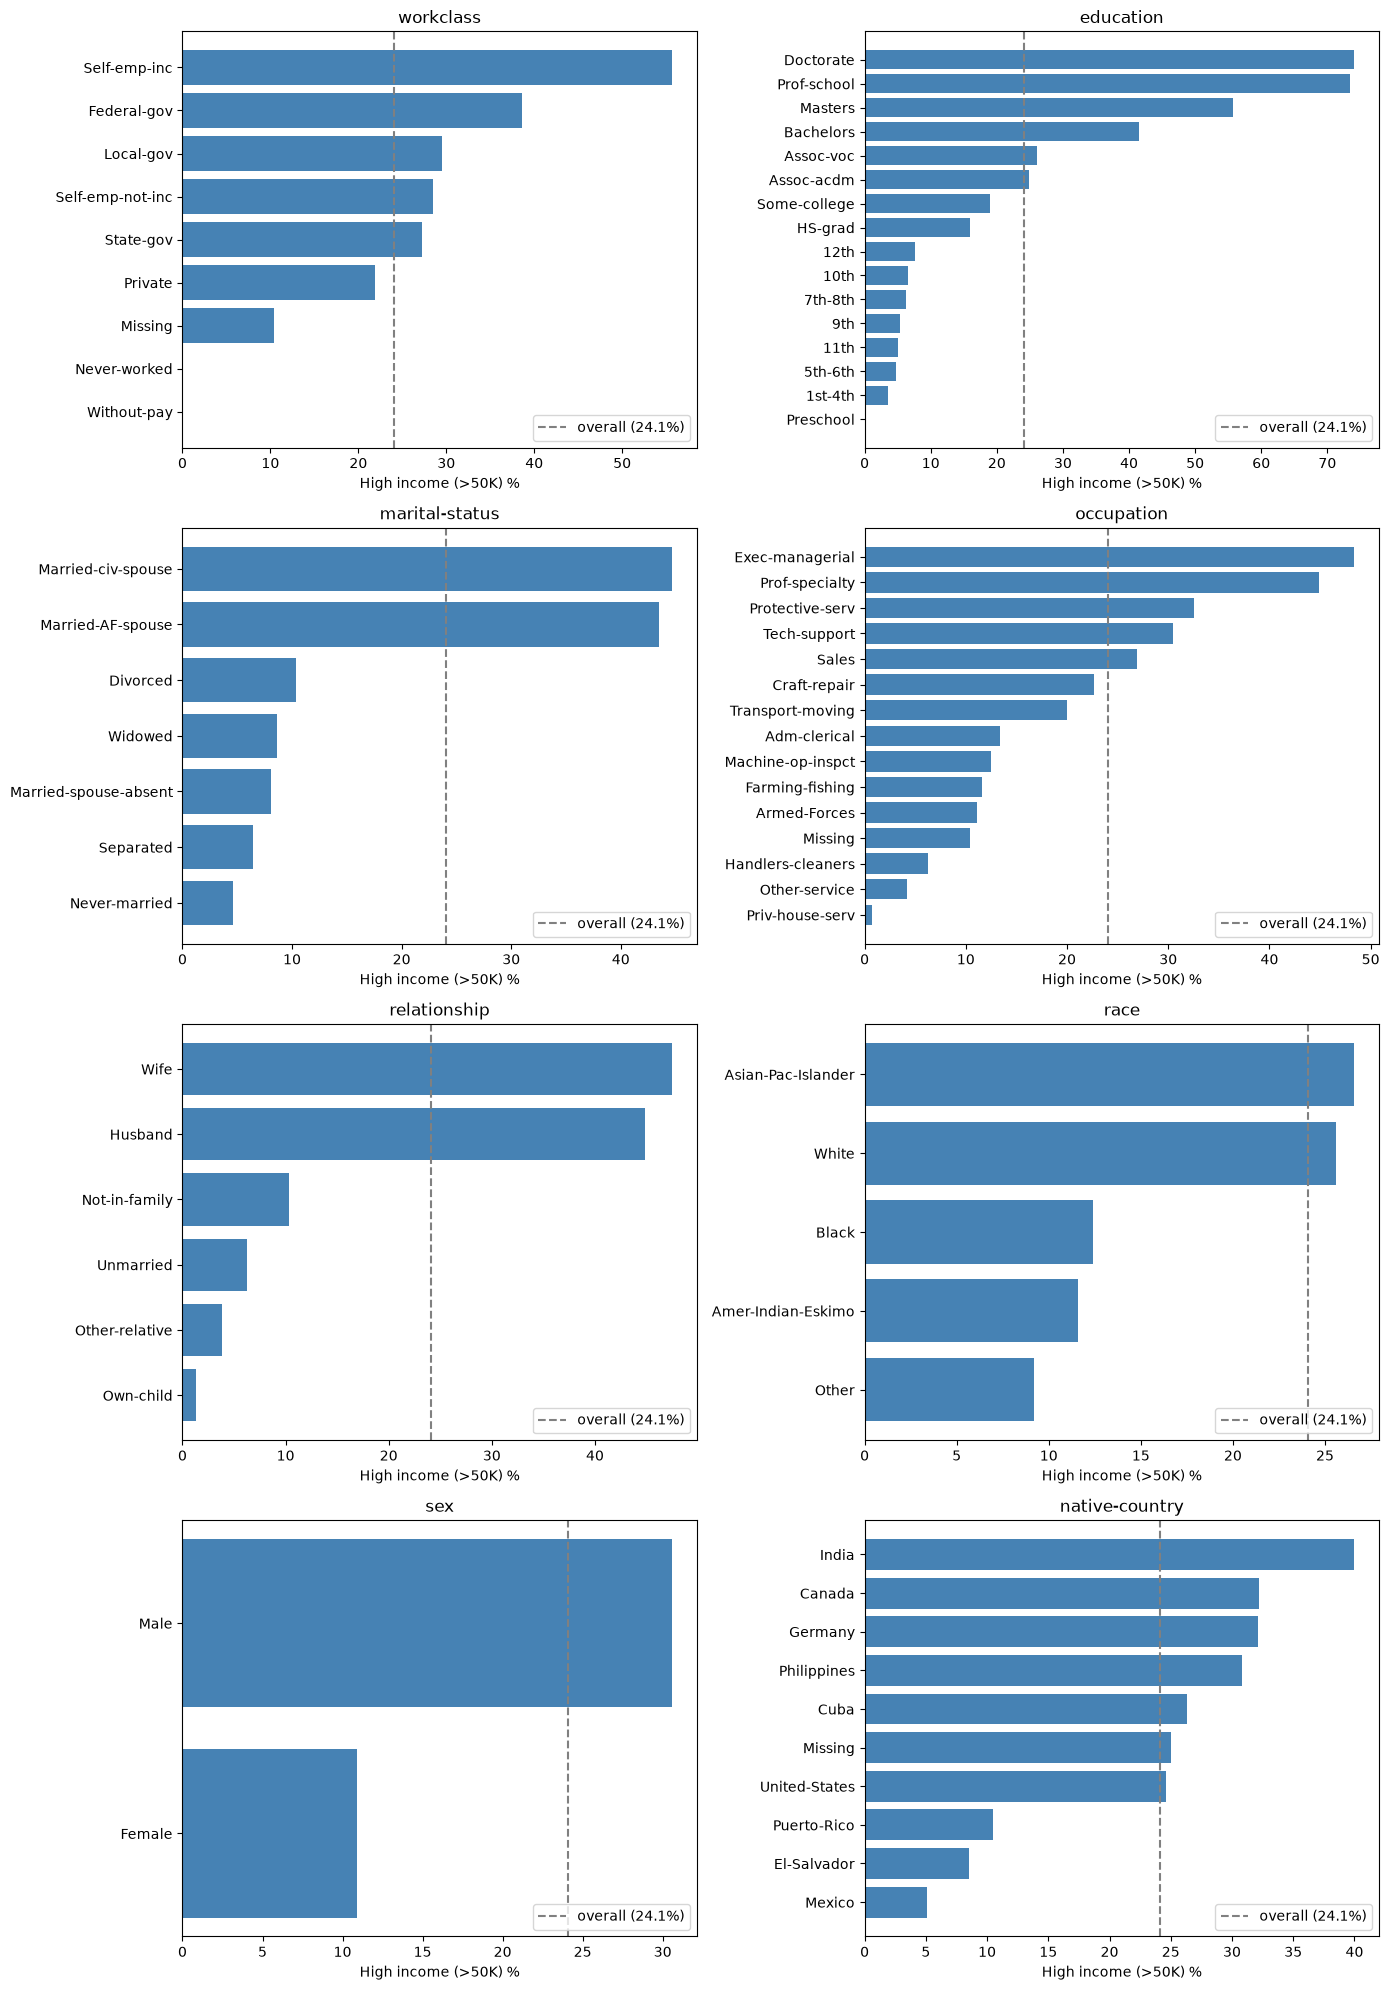

In [33]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))
overall = is_high.mean() * 100       # 전체 고소득자 비율 (약 24%)

for ax, col in zip(axes.flatten(), categorical_cols):
    summary = category_summary(col)

    # native-country는 값이 너무 많으므로, 인원이 많은 상위 10개 나라만 그린다.
    if col == "native-country":
        summary = summary.sort_values("count", ascending=False).head(10)
        summary = summary.sort_values("high_income_pct", ascending=False)

    # barh: 가로 막대그래프. 값 이름이 길어서 세로 막대보다 읽기 쉽다.
    ax.barh(summary.index, summary["high_income_pct"], color="steelblue")

    # 전체 비율을 세로 점선으로 표시 → 이 선보다 길면 평균보다 고소득자가 많은 그룹
    ax.axvline(overall, color="gray", linestyle="--", label=f"overall ({overall:.1f}%)")

    ax.invert_yaxis()                # 비율이 높은 값이 위에 오도록 y축 순서를 뒤집는다.
    ax.set_title(col)
    ax.set_xlabel("High income (>50K) %")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [34]:
# 인원이 너무 적은 값은 고소득자 비율을 믿기 어렵다.
# 예: 2명 중 2명이 고소득자 → 100%지만, 우연일 가능성이 크다.
RARE_MIN = 50    # 50명 미만이면 "드문 값"으로 본다 (기준은 분석하는 사람이 정한다)

for col in categorical_cols:
    counts = train[col].value_counts()
    rare = counts[counts < RARE_MIN]
    if len(rare) > 0:
        # dict(): {값: 인원수} 형태로 바꿔서 한 줄에 보여준다.
        print(f"{col}: {len(rare)}개 → {dict(rare)}")

workclass: 2개 → {'Without-pay': np.int64(14), 'Never-worked': np.int64(7)}
marital-status: 1개 → {'Married-AF-spouse': np.int64(23)}
occupation: 1개 → {'Armed-Forces': np.int64(9)}
native-country: 20개 → {'Haiti': np.int64(44), 'Iran': np.int64(43), 'Portugal': np.int64(37), 'Nicaragua': np.int64(34), 'Peru': np.int64(31), 'France': np.int64(29), 'Greece': np.int64(29), 'Ecuador': np.int64(28), 'Ireland': np.int64(24), 'Hong': np.int64(20), 'Cambodia': np.int64(19), 'Trinadad&Tobago': np.int64(19), 'Thailand': np.int64(18), 'Laos': np.int64(18), 'Yugoslavia': np.int64(16), 'Outlying-US(Guam-USVI-etc)': np.int64(14), 'Honduras': np.int64(13), 'Hungary': np.int64(13), 'Scotland': np.int64(12), 'Holand-Netherlands': np.int64(1)}


In [35]:
# 각 항목에 "어떤 값들이 있는지"만 비교한다 (값의 분포나 정답은 보지 않음).
# 목적: 테스트에만 있는 값이 있으면, 학습한 모델이 처음 보는 값을 만나 오류가 날 수 있다.
for col in categorical_cols:
    train_vals = set(train[col].dropna().unique())   # set: 중복 없는 값의 모음
    test_vals = set(test[col].dropna().unique())

    only_train = train_vals - test_vals    # 집합의 차: 학습에만 있는 값
    only_test = test_vals - train_vals     # 테스트에만 있는 값

    if only_train or only_test:            # 둘 중 하나라도 비어 있지 않으면 출력
        print(f"{col}: 학습에만 {only_train}, 테스트에만 {only_test}")

native-country: 학습에만 {'Holand-Netherlands'}, 테스트에만 set()


In [36]:
# relationship의 Husband(남편)는 거의 남자이고 결혼한 사람일 것이다.
# 정말 그런지 교차표로 확인한다.
display(pd.crosstab(train["relationship"], train["sex"]))
display(pd.crosstab(train["relationship"], train["marital-status"]))

sex,Female,Male
relationship,,
Husband,1,13192
Not-in-family,3875,4430
Other-relative,430,551
Own-child,2245,2823
Unmarried,2654,792
Wife,1566,2


marital-status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,9,13184,0,0,0,0
Not-in-family,2404,0,17,211,4706,420,547
Other-relative,110,1,124,32,611,55,48
Own-child,328,1,95,45,4485,99,15
Unmarried,1601,0,0,130,881,451,383
Wife,0,12,1556,0,0,0,0


In [37]:
# 값을 세 그룹으로 나눈다: 미국 / 다른 나라 / Missing
country = train["native-country"].fillna("Missing")

# np.where(조건, 참일 때 값, 거짓일 때 값): 조건에 따라 값을 고른다. 두 번 겹쳐서 세 그룹을 만든다.
country_group = np.where(country == "United-States", "United-States",
                np.where(country == "Missing", "Missing", "Other"))

# 넘파이 배열을 pandas Series로 바꿔서 groupby에 쓴다 (인덱스를 train과 맞춤)
country_group = pd.Series(country_group, index=train.index)

pd.DataFrame({
    "count": country_group.value_counts(),
    "pct": (country_group.value_counts(normalize=True) * 100).round(1),
    "high_income_pct": (is_high.groupby(country_group).mean() * 100).round(1),
})

,count,pct,high_income_pct
Missing,583,1.8,25.0
Other,2808,8.6,18.7
United-States,29170,89.6,24.6


### 글자 항목 정리
- 고소득자 비율 차이가 가장 큰 항목: relationship (최고 Wife 47.5%, 최저 Own-child 1.3%)
  - education은 Doctorate 74.1% vs Preschool 0.0%로 차이가 더 크지만, Preschool은 51명뿐인 드문 값
- marital-status: Married-civ-spouse 44.7% vs Never-married 4.6% → 약 10배 차이
- occupation: 최고 Exec-managerial 48.4%, 최저 Priv-house-serv 0.7%
- workclass: Self-emp-inc(법인 자영업) 55.7%로 가장 높고, Private(민간 회사)는 21.9%
- sex: Male 30.6% vs Female 10.9%, race: Asian-Pac-Islander 26.6%, White 25.6%, Black 12.4%
- education 순서와 고소득자 비율 순서가 거의 일치 (Doctorate 74.1% → Preschool 0.0%) → education-num만 사용하는 결정 타당
- workclass/occupation의 Missing 그룹 고소득자 비율 10.4% → 2단계 결과와 일치
- 드문 값(50명 미만): workclass 2개(Without-pay 14, Never-worked 7), marital-status 1개(Married-AF-spouse 23), occupation 1개(Armed-Forces 9), native-country 20개 (Holand-Netherlands는 1명)
- 학습/테스트 값 종류 차이: native-country의 Holand-Netherlands가 학습 데이터에만 있음 (테스트에만 있는 값은 없음)
- relationship은 sex, marital-status와 강하게 겹침: Husband 13,193명 중 13,192명이 남자, Wife 1,568명 중 1,566명이 여자, Husband/Wife는 전원 결혼 상태 → Naive Bayes의 독립 가정이 깨지는 예
- native-country: 미국 89.6%, 기타 8.6%, Missing 1.8% → 고소득자 비율은 미국 24.6%, 기타 18.7%, Missing 25.0% → 드문 나라 묶기 검토
- sex, race의 차이는 과거(1994년) 사회 불평등이 반영된 것 → 리포트에 한계로 언급

## 6. 상관관계
- 숫자 항목끼리, 그리고 정답과의 상관계수 (피어슨, 스피어만)
- 글자 항목과 정답의 관계 (크라메르 V)
- 글자 항목끼리 겹치는 정보 확인

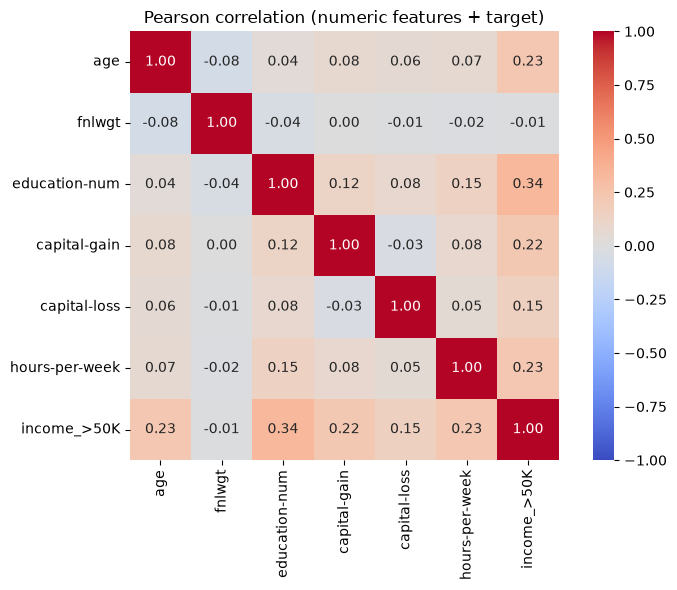

In [38]:
# 상관계수는 숫자끼리만 계산할 수 있으므로, 정답을 0/1 숫자로 바꿔서 함께 넣는다.
# astype(int): True → 1, False → 0
corr_df = train[numeric_cols].copy()       # copy(): 원본 train을 건드리지 않도록 복사본을 만든다.
corr_df["income_>50K"] = is_high.astype(int)

# corr(): 모든 열 쌍의 상관계수를 표로 계산한다.
pearson = corr_df.corr(method="pearson")

# heatmap(히트맵): 표의 숫자를 색으로 칠한 그림
plt.figure(figsize=(8, 6))
sns.heatmap(
    pearson,
    annot=True,          # 칸마다 숫자를 적는다.
    fmt=".2f",           # 소수점 둘째 자리까지
    cmap="coolwarm",     # 음수는 파랑, 양수는 빨강
    vmin=-1, vmax=1,     # 색의 범위를 -1~1로 고정 → 0이 흰색이 된다.
    square=True,         # 칸을 정사각형으로
)
plt.title("Pearson correlation (numeric features + target)")
plt.tight_layout()
plt.show()

In [39]:
# 스피어만: 값 대신 순위로 계산 → 치우친 분포나 극단적인 값에 덜 민감하다.
spearman = corr_df.corr(method="spearman")

# 정답과의 상관계수만 뽑아서 나란히 비교한다.
target_corr = pd.DataFrame({
    "pearson": pearson["income_>50K"],
    "spearman": spearman["income_>50K"],
}).drop("income_>50K")       # 정답 자기 자신과의 상관계수(=1)는 뺀다.

target_corr = target_corr.sort_values("spearman", ascending=False).round(3)
target_corr

,pearson,spearman
education-num,0.335,0.330
capital-gain,0.223,0.278
age,0.234,0.273
hours-per-week,0.230,0.269
capital-loss,0.151,0.141
fnlwgt,-0.009,-0.011


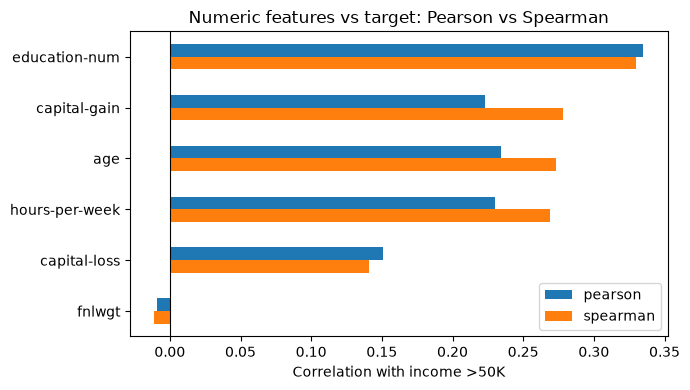

In [40]:
ax = target_corr.plot(kind="barh", figsize=(7, 4))
ax.axvline(0, color="black", linewidth=0.8)   # 0 기준선
ax.invert_yaxis()                             # 큰 값이 위로
ax.set_xlabel("Correlation with income >50K")
ax.set_title("Numeric features vs target: Pearson vs Spearman")
plt.tight_layout()
plt.show()

In [41]:
# chi2_contingency: 카이제곱 검정(chi-square test)
#   두 글자 항목이 서로 무관하다면 교차표의 숫자가 "이론상 기대값"과 비슷해야 한다.
#   실제 값과 기대값의 차이가 클수록 카이제곱 값(chi2)이 커진다 = 관련이 크다.
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """두 글자 항목의 크라메르 V (0 = 무관, 1 = 완전히 같은 정보)"""
    table = pd.crosstab(x, y)                  # 교차표
    chi2 = chi2_contingency(table)[0]          # [0]: 결과 중 첫 번째가 카이제곱 값
    n = table.to_numpy().sum()                 # 전체 인원
    r, k = table.shape                         # 교차표의 행 개수, 열 개수
    # 카이제곱 값은 인원과 값 종류가 많을수록 커지므로, 0~1 범위로 맞추기 위해 나눠준다.
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

In [42]:
# 2단계 결정대로 빈 칸은 "Missing"으로 채워서 계산한다.
# 딕셔너리 컴프리헨션: {키: 값 for ...} 형태로 딕셔너리를 한 줄에 만든다.
cat_target = pd.Series({
    col: cramers_v(train[col].fillna("Missing"), train[TARGET])
    for col in categorical_cols
}).sort_values(ascending=False).round(3)

cat_target

relationship      0.454
marital-status    0.447
education         0.369
occupation        0.352
sex               0.216
workclass         0.179
race              0.101
native-country    0.099
dtype: float64

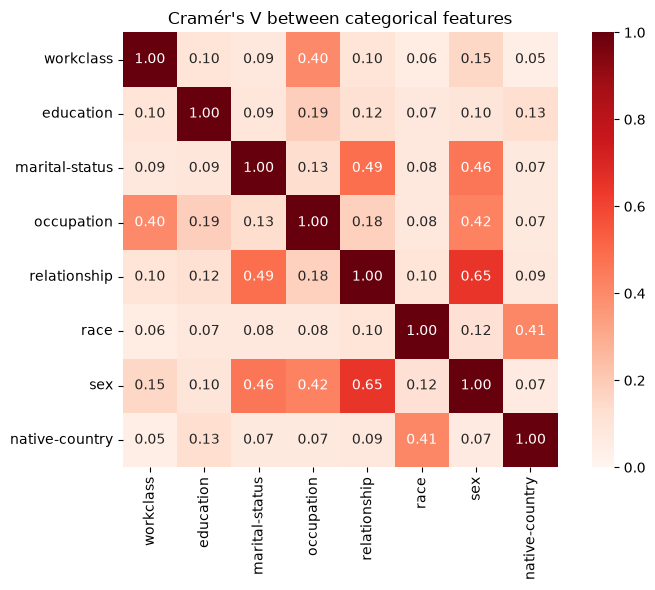

In [43]:
cat_data = train[categorical_cols].fillna("Missing")

# 빈 표를 만들고, 모든 쌍에 대해 크라메르 V를 채운다.
cv_matrix = pd.DataFrame(index=categorical_cols, columns=categorical_cols, dtype=float)
for a in categorical_cols:
    for b in categorical_cols:
        cv_matrix.loc[a, b] = cramers_v(cat_data[a], cat_data[b])

plt.figure(figsize=(8, 6))
sns.heatmap(cv_matrix, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, square=True)
plt.title("Cramér's V between categorical features")
plt.tight_layout()
plt.show()

### 상관관계 정리
- 숫자 항목과 정답의 상관 (스피어만 기준 순위): education-num 0.330 > capital-gain 0.278 > age 0.273 > hours-per-week 0.269 > capital-loss 0.141 > fnlwgt -0.011
- 숫자 항목끼리의 상관: 가장 큰 쌍 education-num과 hours-per-week (0.148) → 모든 쌍이 0.15 이하 → 다중공선성 거의 없음, 숫자 항목들이 서로 다른 정보를 담고 있음
- fnlwgt와 정답의 상관: 피어슨 -0.009, 스피어만 -0.011 → 사실상 0 → 4단계(두 그룹 분포가 거의 같음)와 함께 제외 근거
- capital-gain: 피어슨 0.223 vs 스피어만 0.278 → 순위 기반인 스피어만이 더 높음 → 극단적인 값(99999)과 0이 92%인 분포 때문에 피어슨이 관계를 과소평가
- 글자 항목과 정답의 크라메르 V 순위: relationship 0.454 > marital-status 0.447 > education 0.369 > occupation 0.352 > sex 0.216 > workclass 0.179 > race 0.101 > native-country 0.099
- 글자 항목끼리 강하게 겹치는 쌍: relationship–sex 0.649, relationship–marital-status 0.488, marital-status–sex 0.462 → Naive Bayes 독립 가정 위반
- 그 외 겹치는 쌍: occupation–sex 0.424, race–native-country 0.409, workclass–occupation 0.400 (두 항목의 Missing이 같은 사람들이라서 생긴 관계)
- 한계: 상관관계는 두 항목 사이의 관계만 보므로, 여러 항목이 함께 작용하는 효과는 모델 실험에서 확인해야 함

## 7. 탐색적 데이터 분석 최종 결론

### 7.1 데이터 요약
- UCI Adult (1994년 미국 인구 조사), 학습 32,561행 / 테스트 16,281행, 숫자 항목 6개 + 글자 항목 8개
- 목표: 연소득 50K 초과 여부 이진 분류, 50K 초과 비율 24.08% (테스트 23.62%)

### 7.2 핵심 발견
1. **중간 정도의 불균형 (3.15 : 1)**: 항상 '<=50K'만 예측해도 정확도 75.92% → 정확도만으로는 평가 불가
2. **빈 칸은 무작위가 아님**: workclass/occupation이 빈 칸인 사람의 고소득자 비율 10.4% (전체 24.1%). 이들은 학생, 은퇴자 등 현재 일하지 않는 사람이 많음 → 빈 칸 자체가 정보
3. **가장 강한 신호는 결혼 여부**: relationship(크라메르 V 0.454), marital-status(0.447). 기혼자 고소득자 비율 약 45% vs 미혼 4.6%
4. **숫자 항목 중 압도적인 항목은 없음**: education-num(0.330), capital-gain, age, hours-per-week(0.27~0.28)가 비슷한 수준 → 여러 항목을 함께 써야 함
5. **capital-gain/loss는 "0인가 아닌가"가 핵심**: 92%, 95%가 0이지만, 0이 아니면 고소득자 비율이 61.8%, 50.9%. capital-gain 99999인 159명은 100% 고소득자 → 직선이 아닌 관계
6. **fnlwgt는 정답과 무관**: 상관계수 -0.009, 두 그룹의 분포도 거의 같음. 의미상으로도 개인 특성이 아닌 표본 가중치
7. **겹치는 정보**: education ↔ education-num (1대1 대응), relationship ↔ sex (0.649), relationship ↔ marital-status (0.488)
8. **숫자 항목끼리는 독립적**: 모든 쌍의 상관계수가 0.15 이하 → 다중공선성 문제 없음
9. **항목마다 범위 차이가 큼**: education-num 1~16 vs capital-gain 0~99,999

### 7.3 전처리 결정 (src/preprocess.py에 반영)
| 대상 | 처리 | 근거 |
|---|---|---|
| education | 제외 | education-num과 같은 정보 (1단계) |
| fnlwgt | 제외 | 정답과 상관 없음 + 표본 가중치 (4, 6단계) |
| 글자 항목의 빈 칸 | "Missing"이라는 별도 값으로 채움 | 빈 칸 자체가 정보 (2단계) |
| 글자 항목 | One-hot encoding, 드문 값(50명 미만)은 하나로 묶음, 처음 보는 값은 무시 | 드문 값 다수, 특히 native-country 20개 (5단계) |
| capital-gain, capital-loss | log1p 변환 (+ "0인가 아닌가" 열 추가 실험) | 심한 치우침, 0이 대부분 (4단계) |
| 숫자 항목 | StandardScaler (scaling에 민감한 모델용) | 범위 차이가 큼 (4단계) |
| 상한값 (99999, 99, 90) | 그대로 유지 | 입력 오류가 아닌 상한값 처리 (4단계) |
| 전체 | sklearn Pipeline + ColumnTransformer로 학습 데이터에만 fit | 데이터 누수 방지 |

### 7.4 평가 방법
- 지표: ROC-AUC, PR-AUC, F1, balanced accuracy, confusion matrix (정확도는 참고용)
- 기준선: Dummy 모델 (학습 정확도 75.92%, 테스트 76.38%, F1 = 0)
- 교차 검증: StratifiedKFold (조각마다 76:24 비율 유지)
- 불균형 대응 실험: class_weight="balanced", 판정 기준값(0.5) 조정

### 7.5 모델별 실험 전 예상
| 모델 | 예상 | 탐색적 데이터 분석 근거 |
|---|---|---|
| Linear / Polynomial Regression | 기준선보다는 낫지만 한계가 있음. Polynomial은 열이 폭발적으로 늘어남 | 출력이 0~1을 벗어남, one-hot 후 열이 약 90개 |
| Perceptron | 학습이 수렴하지 않고 결과가 불안정 | 압도적인 항목이 없고 두 그룹의 분포가 많이 겹침 → 직선으로 나뉘지 않음 |
| SVM | scaling을 하면 좋은 성능. RBF kernel은 학습이 느림 | 범위 차이, 직선이 아닌 관계, 3만 행 |
| k-NN | scaling 여부에 따라 성능 차이가 큼. 예측이 느림 | 범위 차이, one-hot 후 고차원 (차원의 저주) |
| Decision Tree | scaling 불필요. 첫 분기는 결혼 여부, capital-gain 기준값을 잘 찾음. 깊으면 과적합 | 결혼 여부가 가장 강한 신호, capital-gain은 "어느 값 이상이냐"의 관계 |
| Naive Bayes | 확률이 한쪽으로 과하게 치우침. 순위 기반 지표(ROC-AUC)는 비교적 괜찮을 수 있음 | relationship, sex, marital-status가 겹쳐 독립 가정 위반, capital-gain은 정규분포가 아님 |
| (진도 후) 앙상블 계열 | 가장 좋은 성능 예상 | 중간 강도의 항목 여러 개 + 직선이 아닌 관계 → 여러 트리의 조합이 유리 |

### 7.6 한계
- 1994년 데이터로, 현재의 소득 구조와 다를 수 있음
- sex, race의 차이는 과거 사회 불평등이 반영된 것 → 모델이 이를 그대로 학습함
- 상관관계는 두 항목 사이의 관계만 보므로, 여러 항목이 함께 작용하는 효과는 모델 실험에서 확인해야 함